Load the dataset

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("dylanjcastillo/7k-books-with-metadata")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\udhay\.cache\kagglehub\datasets\dylanjcastillo\7k-books-with-metadata\versions\3


Read the book dataset

In [2]:
import pandas as pd

book_ds = pd.read_csv(f"{path}\\books.csv")

In [3]:
book_ds.head()

,isbn13,isbn10,title,subtitle,authors,categories,thumbnail,description,published_year,average_rating,num_pages,ratings_count
0,9780002005883,0002005883,Gilead,NaN,Marilynne Robinson,Fiction,http://books.google.com/books/content?id=KQZCP...,A NOVEL THAT READERS and critics have been eag...,2004.0,3.85,247.0,361.0
1,9780002261982,0002261987,Spider's Web,A Novel,Charles Osborne;Agatha Christie,Detective and mystery stories,http://books.google.com/books/content?id=gA5GP...,A new 'Christie for Christmas' -- a full-lengt...,2000.0,3.83,241.0,5164.0
2,9780006163831,0006163831,The One Tree,NaN,Stephen R. Donaldson,American fiction,http://books.google.com/books/content?id=OmQaw...,Volume Two of Stephen Donaldson's acclaimed se...,1982.0,3.97,479.0,172.0
3,9780006178736,0006178731,Rage of angels,NaN,Sidney Sheldon,Fiction,http://books.google.com/books/content?id=FKo2T...,"A memorable, mesmerizing heroine Jennifer -- b...",1993.0,3.93,512.0,29532.0
4,9780006280897,0006280897,The Four Loves,NaN,Clive Staples Lewis,Christian life,http://books.google.com/books/content?id=XhQ5X...,Lewis' work on the nature of love divides love...,2002.0,4.15,170.0,33684.0


In [4]:
book_ds.info()

<class 'pandas.DataFrame'>
RangeIndex: 6810 entries, 0 to 6809
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   isbn13          6810 non-null   int64  
 1   isbn10          6810 non-null   str    
 2   title           6810 non-null   str    
 3   subtitle        2381 non-null   str    
 4   authors         6738 non-null   str    
 5   categories      6711 non-null   str    
 6   thumbnail       6481 non-null   str    
 7   description     6548 non-null   str    
 8   published_year  6804 non-null   float64
 9   average_rating  6767 non-null   float64
 10  num_pages       6767 non-null   float64
 11  ratings_count   6767 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 638.6 KB


Text(50.38563368055554, 0.5, 'Missing Values')

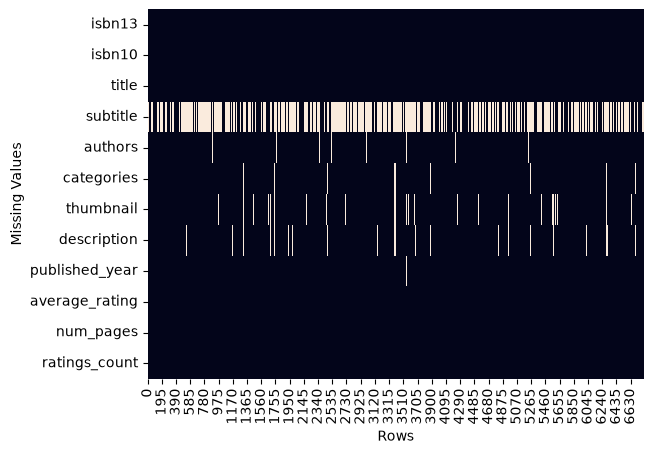

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

ax = plt.axes()
sns.heatmap(book_ds.isna().transpose(), cbar=False, ax=ax)

plt.xlabel("Rows")
plt.ylabel("Missing Values")

In [6]:
import numpy as np

book_ds["missing_description"] = np.where(book_ds["description"].isna(),1,0)
book_ds["age_of_book"] = 2026 - book_ds["published_year"]

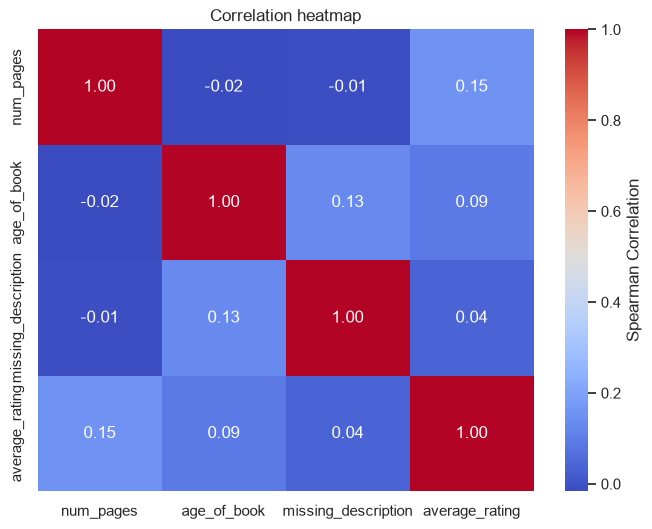

In [7]:
columns_of_interest = ["num_pages", "age_of_book", "missing_description", "average_rating"]

correlation_matrix = book_ds[columns_of_interest].corr(method="spearman")

sns.set_theme(style="white")
plt.figure(figsize=(8,6))
heatmap = sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm",
                      cbar_kws={"label": "Spearman Correlation"})

heatmap.set_title("Correlation heatmap")
plt.show()

Since there is no clear correlation between missing descriptions and our chosen features, and given few descriptions are actually missing, we can just just rows with missing descriptions.

In [8]:
book_missing = book_ds[~(book_ds["description"].isna()) & 
        ~(book_ds["num_pages"].isna()) & 
        ~(book_ds["average_rating"].isna()) &
        ~(book_ds["published_year"].isna())
        ]

book_missing

,isbn13,isbn10,title,subtitle,authors,categories,thumbnail,description,published_year,average_rating,num_pages,ratings_count,missing_description,age_of_book
0,9780002005883,0002005883,Gilead,NaN,Marilynne Robinson,Fiction,http://books.google.com/books/content?id=KQZCP...,A NOVEL THAT READERS and critics have been eag...,2004.0,3.85,247.0,361.0,0,22.0
1,9780002261982,0002261987,Spider's Web,A Novel,Charles Osborne;Agatha Christie,Detective and mystery stories,http://books.google.com/books/content?id=gA5GP...,A new 'Christie for Christmas' -- a full-lengt...,2000.0,3.83,241.0,5164.0,0,26.0
2,9780006163831,0006163831,The One Tree,NaN,Stephen R. Donaldson,American fiction,http://books.google.com/books/content?id=OmQaw...,Volume Two of Stephen Donaldson's acclaimed se...,1982.0,3.97,479.0,172.0,0,44.0
3,9780006178736,0006178731,Rage of angels,NaN,Sidney Sheldon,Fiction,http://books.google.com/books/content?id=FKo2T...,"A memorable, mesmerizing heroine Jennifer -- b...",1993.0,3.93,512.0,29532.0,0,33.0
4,9780006280897,0006280897,The Four Loves,NaN,Clive Staples Lewis,Christian life,http://books.google.com/books/content?id=XhQ5X...,Lewis' work on the nature of love divides love...,2002.0,4.15,170.0,33684.0,0,24.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6803,9788173031014,8173031010,Journey to the East,NaN,Hermann Hesse,Adventure stories,http://books.google.com/books/content?id=rq6JP...,This book tells the tale of a man who goes on ...,2002.0,3.70,175.0,24.0,0,24.0
6804,9788179921623,817992162X,The Monk Who Sold His Ferrari: A Fable About F...,NaN,Robin Sharma,Health & Fitness,http://books.google.com/books/content?id=c_7mf...,"Wisdom to Create a Life of Passion, Purpose, a...",2003.0,3.82,198.0,1568.0,0,23.0
6805,9788185300535,8185300534,I Am that,Talks with Sri Nisargadatta Maharaj,Sri Nisargadatta Maharaj;Sudhakar S. Dikshit,Philosophy,http://books.google.com/books/content?id=Fv_JP...,This collection of the timeless teachings of o...,1999.0,4.51,531.0,104.0,0,27.0
6808,9789027712059,9027712050,The Berlin Phenomenology,NaN,Georg Wilhelm Friedrich Hegel,History,http://books.google.com/books/content?id=Vy7Sk...,Since the three volume edition ofHegel's Philo...,1981.0,0.00,210.0,0.0,0,45.0


In [9]:
book_missing["categories"].unique()

<StringArray>
[                              'Fiction',
         'Detective and mystery stories',
                      'American fiction',
                        'Christian life',
                      'Authors, English',
                          'Africa, East',
   'Hyland, Morn (Fictitious character)',
                     'Adventure stories',
                    'Arthurian romances',
                       'Fantasy fiction',
 ...
               'Adjustment (Psychology)',
                     'Boats and boating',
       'People with social disabilities',
 'Minimal brain dysfunction in children',
                        'Spiritual life',
                            'Meditation',
                               'Gay men',
                     'Christian fiction',
            'Napoleonic Wars, 1800-1815',
               'Indic fiction (English)']
Length: 532, dtype: str

In [10]:
unique_categories = book_missing["categories"].value_counts().reset_index().sort_values("count", ascending=False)

unique_categories

,categories,count
0,Fiction,2523
1,Juvenile Fiction,534
2,Biography & Autobiography,391
3,History,258
4,Literary Criticism,164
...,...,...
526,Meditation,1
527,Gay men,1
528,Christian fiction,1
529,"Napoleonic Wars, 1800-1815",1


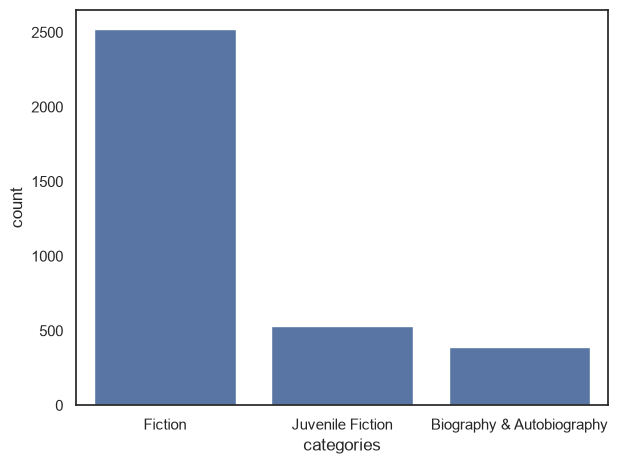

In [11]:
sns.barplot(data=unique_categories.loc[0:2], x="categories", y="count")
plt.tight_layout()

There is clearly a disproportionate amount of Fiction books.

In [12]:
book_missing["words_in_description"] = book_missing["description"].str.split().str.len()

In [13]:
book_missing

,isbn13,isbn10,title,subtitle,authors,categories,thumbnail,description,published_year,average_rating,num_pages,ratings_count,missing_description,age_of_book,words_in_description
0,9780002005883,0002005883,Gilead,NaN,Marilynne Robinson,Fiction,http://books.google.com/books/content?id=KQZCP...,A NOVEL THAT READERS and critics have been eag...,2004.0,3.85,247.0,361.0,0,22.0,199
1,9780002261982,0002261987,Spider's Web,A Novel,Charles Osborne;Agatha Christie,Detective and mystery stories,http://books.google.com/books/content?id=gA5GP...,A new 'Christie for Christmas' -- a full-lengt...,2000.0,3.83,241.0,5164.0,0,26.0,205
2,9780006163831,0006163831,The One Tree,NaN,Stephen R. Donaldson,American fiction,http://books.google.com/books/content?id=OmQaw...,Volume Two of Stephen Donaldson's acclaimed se...,1982.0,3.97,479.0,172.0,0,44.0,14
3,9780006178736,0006178731,Rage of angels,NaN,Sidney Sheldon,Fiction,http://books.google.com/books/content?id=FKo2T...,"A memorable, mesmerizing heroine Jennifer -- b...",1993.0,3.93,512.0,29532.0,0,33.0,57
4,9780006280897,0006280897,The Four Loves,NaN,Clive Staples Lewis,Christian life,http://books.google.com/books/content?id=XhQ5X...,Lewis' work on the nature of love divides love...,2002.0,4.15,170.0,33684.0,0,24.0,45
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6803,9788173031014,8173031010,Journey to the East,NaN,Hermann Hesse,Adventure stories,http://books.google.com/books/content?id=rq6JP...,This book tells the tale of a man who goes on ...,2002.0,3.70,175.0,24.0,0,24.0,63
6804,9788179921623,817992162X,The Monk Who Sold His Ferrari: A Fable About F...,NaN,Robin Sharma,Health & Fitness,http://books.google.com/books/content?id=c_7mf...,"Wisdom to Create a Life of Passion, Purpose, a...",2003.0,3.82,198.0,1568.0,0,23.0,117
6805,9788185300535,8185300534,I Am that,Talks with Sri Nisargadatta Maharaj,Sri Nisargadatta Maharaj;Sudhakar S. Dikshit,Philosophy,http://books.google.com/books/content?id=Fv_JP...,This collection of the timeless teachings of o...,1999.0,4.51,531.0,104.0,0,27.0,174
6808,9789027712059,9027712050,The Berlin Phenomenology,NaN,Georg Wilhelm Friedrich Hegel,History,http://books.google.com/books/content?id=Vy7Sk...,Since the three volume edition ofHegel's Philo...,1981.0,0.00,210.0,0.0,0,45.0,245


In [20]:
book_missing.loc[book_missing["words_in_description"].between(1,4)].head()

,isbn13,isbn10,title,subtitle,authors,categories,thumbnail,description,published_year,average_rating,num_pages,ratings_count,missing_description,age_of_book,words_in_description
6,9780006353287,0006353282,An Autobiography,NaN,Agatha Christie,"Authors, English",http://books.google.com/books/content?id=c49GQ...,Donation.,1977.0,4.27,560.0,3975.0,0,49.0,1
11,9780006480099,0006480098,Assassin's Apprentice,NaN,Robin Hobb,American fiction,http://books.google.com/books/content?id=qTaGQ...,Fantasy-roman.,1996.0,4.15,460.0,133972.0,0,30.0,1
748,9780140289237,0140289232,For Lust of Knowing,The Orientalists and Their Enemies,Robert Irwin,Art,http://books.google.com/books/content?id=fji7C...,Includes bibliographical references.,2007.0,3.70,304.0,10.0,0,19.0,3
770,9780140383195,0140383190,Bound for Oregon,NaN,Jean Van Leeuwen,Juvenile Fiction,http://books.google.com/books/content?id=b8YxN...,Bound For Oregon (PB),1996.0,3.78,176.0,817.0,0,30.0,4
775,9780140430899,014043089X,De Profundis and Other Writings,NaN,Oscar Wilde,Fiction,http://books.google.com/books/content?id=ANYo1...,No Marketing Blurb,1973.0,4.21,252.0,2253.0,0,53.0,3


In [21]:
book_missing.loc[book_missing["words_in_description"].between(1,4)].shape[0]

55

In [22]:
book_missing.loc[book_missing["words_in_description"].between(5,14)].head()

,isbn13,isbn10,title,subtitle,authors,categories,thumbnail,description,published_year,average_rating,num_pages,ratings_count,missing_description,age_of_book,words_in_description
2,9780006163831,0006163831,The One Tree,NaN,Stephen R. Donaldson,American fiction,http://books.google.com/books/content?id=OmQaw...,Volume Two of Stephen Donaldson's acclaimed se...,1982.0,3.97,479.0,172.0,0,44.0,14
38,9780007103676,0007103670,Koko,NaN,Peter Straub,Male friendship,http://books.google.com/books/content?id=QV_XQ...,Koko is Peter Straub's foray into the psycholo...,2001.0,3.56,634.0,7586.0,0,25.0,13
70,9780007150304,000715030X,"Beware, Princess Elizabeth",NaN,Carolyn Meyer,Children's stories,http://books.google.com/books/content?id=wPBpR...,A matter of life and death - and the Throne of...,2003.0,3.88,242.0,78.0,0,23.0,12
77,9780007158515,0007158513,I Can Read with Me Eyes Shut!,NaN,Dr. Seuss,"Authors, American",http://books.google.com/books/content?id=oyF8U...,Nonsense rhyming story. 4 yrs+,2003.0,4.20,48.0,16561.0,0,23.0,5
84,9780007178636,0007178638,There's a Boy in the Girls' Bathroom,NaN,Louis Sachar,Boys,http://books.google.com/books/content?id=jHE-P...,A study guide for the novel There's a Boy in t...,2004.0,3.98,208.0,174.0,0,22.0,13


In [24]:
book_missing.loc[book_missing["words_in_description"].between(5,14)].shape[0]

308

In [25]:
book_missing.loc[book_missing["words_in_description"].between(15,24)].head()

,isbn13,isbn10,title,subtitle,authors,categories,thumbnail,description,published_year,average_rating,num_pages,ratings_count,missing_description,age_of_book,words_in_description
10,9780006479673,0006479677,If Tomorrow Comes,NaN,Sidney Sheldon,Adventure stories,http://books.google.com/books/content?id=l2tBi...,One of Sidney Sheldon's most popular and bests...,1994.0,4.04,501.0,49170.0,0,32.0,18
32,9780006550433,0006550436,The Bonesetter's Daughter,NaN,Amy Tan,China,http://books.google.com/books/content?id=4KHT6...,Tells the story of three generations of Chines...,2001.0,3.98,352.0,414.0,0,25.0,16
36,9780006754893,0006754899,A Small Pinch of Weather,And Other Stories,Joan Aiken,"Children's stories, English",http://books.google.com/books/content?id=QiFhO...,A magical and fantastic collection of early st...,2000.0,4.27,239.0,116.0,0,26.0,24
57,9780007122585,0007122586,The Secret of Chimneys,NaN,Agatha Christie,"Battle, Superintendent (Fictitious character)",http://books.google.com/books/content?id=1OluX...,A young drifter finds more than he bargained f...,2001.0,3.86,400.0,11110.0,0,25.0,21
68,9780007149612,0007149611,Breaking Open the Head,A Visionary Journey from Cynicism to Shamanism,Daniel Pinchbeck,Hallucinogenic drugs,http://books.google.com/books/content?id=QIMav...,A new 'The Doors of Perception' for the 21st c...,2004.0,4.06,336.0,46.0,0,22.0,23


In [26]:
book_missing.loc[book_missing["words_in_description"].between(15,24)].shape[0]

947

In [28]:
pd.set_option('display.max_colwidth', None)

book_missing.loc[book_missing["words_in_description"].between(25,34), ["description"]].head()

,description
9,Kate Blackwell is an enigma and one of the most powerful women in the world. But at her ninetieth birthday celebrations there are ghosts of absent friends and absent enemies.
14,"Available in the U.S. for the first time, this is the second volume in the exceptional Legends of the Riftwar series from ""New York Times""-bestselling authors Feist and Rosenberg."
20,"It is 1937, and Charles Ashworth, a Canon to the Archbishop of Canterbury, is sent to untangle a web of self-delusion and corruption at the episcopal palace of the charismatic Bishop of Starbridge."
21,"Reissue of the author's most famous and well-loved work, the Starbridge series, six self-contained yet interconnected novels that explore the history of the Church of England through the 20th century."
46,"No one believes a little girl when she insists that she has witnessed a murder until she herself turns up drowned, and Hercule Poirot sets out to catch the killer."


This seems to be a good length for informative descriptions!

In [29]:
book_missing_25_words = book_missing.loc[book_missing["words_in_description"] >= 25]

In [31]:
book_missing_25_words.shape[0]

5197

Now, let us deal with the subtitle, which is missing most of its values.

In [33]:
book_missing_25_words["title_and_subtitle"] = np.where(book_missing_25_words["subtitle"].isna(), 
                                                       book_missing_25_words["title"], 
                                                       book_missing_25_words[["title", "subtitle"]].fillna("").astype(str).agg(": ".join, axis=1))

In [35]:
pd.reset_option('display.max_colwidth')

book_missing_25_words.head()

,isbn13,isbn10,title,subtitle,authors,categories,thumbnail,description,published_year,average_rating,num_pages,ratings_count,missing_description,age_of_book,words_in_description,title_and_subtitle
0,9780002005883,0002005883,Gilead,NaN,Marilynne Robinson,Fiction,http://books.google.com/books/content?id=KQZCP...,A NOVEL THAT READERS and critics have been eag...,2004.0,3.85,247.0,361.0,0,22.0,199,Gilead
1,9780002261982,0002261987,Spider's Web,A Novel,Charles Osborne;Agatha Christie,Detective and mystery stories,http://books.google.com/books/content?id=gA5GP...,A new 'Christie for Christmas' -- a full-lengt...,2000.0,3.83,241.0,5164.0,0,26.0,205,Spider's Web: A Novel
3,9780006178736,0006178731,Rage of angels,NaN,Sidney Sheldon,Fiction,http://books.google.com/books/content?id=FKo2T...,"A memorable, mesmerizing heroine Jennifer -- b...",1993.0,3.93,512.0,29532.0,0,33.0,57,Rage of angels
4,9780006280897,0006280897,The Four Loves,NaN,Clive Staples Lewis,Christian life,http://books.google.com/books/content?id=XhQ5X...,Lewis' work on the nature of love divides love...,2002.0,4.15,170.0,33684.0,0,24.0,45,The Four Loves
5,9780006280934,0006280935,The Problem of Pain,NaN,Clive Staples Lewis,Christian life,http://books.google.com/books/content?id=Kk-uV...,"""In The Problem of Pain, C.S. Lewis, one of th...",2002.0,4.09,176.0,37569.0,0,24.0,75,The Problem of Pain


In [36]:
book_missing_25_words["tagged_description"] = book_missing_25_words[["isbn13", "description"]].astype("str").agg(" ".join, axis=1)

In [37]:
book_missing_25_words

,isbn13,isbn10,title,subtitle,authors,categories,thumbnail,description,published_year,average_rating,num_pages,ratings_count,missing_description,age_of_book,words_in_description,title_and_subtitle,tagged_description
0,9780002005883,0002005883,Gilead,NaN,Marilynne Robinson,Fiction,http://books.google.com/books/content?id=KQZCP...,A NOVEL THAT READERS and critics have been eag...,2004.0,3.85,247.0,361.0,0,22.0,199,Gilead,9780002005883 A NOVEL THAT READERS and critics...
1,9780002261982,0002261987,Spider's Web,A Novel,Charles Osborne;Agatha Christie,Detective and mystery stories,http://books.google.com/books/content?id=gA5GP...,A new 'Christie for Christmas' -- a full-lengt...,2000.0,3.83,241.0,5164.0,0,26.0,205,Spider's Web: A Novel,9780002261982 A new 'Christie for Christmas' -...
3,9780006178736,0006178731,Rage of angels,NaN,Sidney Sheldon,Fiction,http://books.google.com/books/content?id=FKo2T...,"A memorable, mesmerizing heroine Jennifer -- b...",1993.0,3.93,512.0,29532.0,0,33.0,57,Rage of angels,"9780006178736 A memorable, mesmerizing heroine..."
4,9780006280897,0006280897,The Four Loves,NaN,Clive Staples Lewis,Christian life,http://books.google.com/books/content?id=XhQ5X...,Lewis' work on the nature of love divides love...,2002.0,4.15,170.0,33684.0,0,24.0,45,The Four Loves,9780006280897 Lewis' work on the nature of lov...
5,9780006280934,0006280935,The Problem of Pain,NaN,Clive Staples Lewis,Christian life,http://books.google.com/books/content?id=Kk-uV...,"""In The Problem of Pain, C.S. Lewis, one of th...",2002.0,4.09,176.0,37569.0,0,24.0,75,The Problem of Pain,"9780006280934 ""In The Problem of Pain, C.S. Le..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6802,9788172235222,8172235224,Mistaken Identity,NaN,Nayantara Sahgal,Indic fiction (English),http://books.google.com/books/content?id=q-tKP...,On A Train Journey Home To North India After L...,2003.0,2.93,324.0,0.0,0,23.0,288,Mistaken Identity,9788172235222 On A Train Journey Home To North...
6803,9788173031014,8173031010,Journey to the East,NaN,Hermann Hesse,Adventure stories,http://books.google.com/books/content?id=rq6JP...,This book tells the tale of a man who goes on ...,2002.0,3.70,175.0,24.0,0,24.0,63,Journey to the East,9788173031014 This book tells the tale of a ma...
6804,9788179921623,817992162X,The Monk Who Sold His Ferrari: A Fable About F...,NaN,Robin Sharma,Health & Fitness,http://books.google.com/books/content?id=c_7mf...,"Wisdom to Create a Life of Passion, Purpose, a...",2003.0,3.82,198.0,1568.0,0,23.0,117,The Monk Who Sold His Ferrari: A Fable About F...,9788179921623 Wisdom to Create a Life of Passi...
6805,9788185300535,8185300534,I Am that,Talks with Sri Nisargadatta Maharaj,Sri Nisargadatta Maharaj;Sudhakar S. Dikshit,Philosophy,http://books.google.com/books/content?id=Fv_JP...,This collection of the timeless teachings of o...,1999.0,4.51,531.0,104.0,0,27.0,174,I Am that: Talks with Sri Nisargadatta Maharaj,9788185300535 This collection of the timeless ...


In [39]:
book_missing_25_words.drop(["subtitle", "missing_description", "age_of_book", "words_in_description"], axis=1).to_csv("books_cleaned.csv", index=False)